In [ ]:
import xarray as xr
import os
import numpy as np

In [ ]:
import glob
from matplotlib import pyplot as plt
import sys
sys.path.append("..")
from src.data.dataset_utils import filter_nodes

In [ ]:
files = [f"/work/bg1602/g260094/SNS/RUN00a/outputs_all/out2d_{day}.nc" for day in range(28, 366)]
files = [f for f in files if os.path.exists(f)]
len(files), files[0], files[-1]

(197,
 '/work/bg1602/g260094/SNS/RUN00a/outputs_all/out2d_28.nc',
 '/work/bg1602/g260094/SNS/RUN00a/outputs_all/out2d_224.nc')

In [ ]:
variables = ["windSpeedX", "windSpeedY", "elevation", "depthAverageVelX", "depthAverageVelY", "sigWaveHeight", "peakPeriod", "meanWavePeriod", "TM10",
             "meanWaveNumber", "meanWaveLength", "meanWaveDirection", "meanDirSpreading",
             "SCHISM_hgrid_face_nodes", "SCHISM_hgrid_edge_nodes", "dryFlagNode", "depth",
             "continuousPeakPeriod", "dominantDirection", "rmsOrbitalVelocity", "bottomExcursionPerio", "peakPhaseVel", "peakWaveLength", "dissRateDepBreaking",
             "rollerDissRate",
             "SCHISM_hgrid_node_x", "SCHISM_hgrid_node_y", "SCHISM_hgrid_face_x", "SCHISM_hgrid_face_y", "SCHISM_hgrid_edge_x", "SCHISM_hgrid_edge_y",
            ]

In [ ]:
ds = xr.open_mfdataset(files, chunks="auto")

/tmp/ipykernel_776818/1482977654.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(files, chunks="auto")


In [ ]:
ds.time.values[-1]

np.datetime64('2020-08-12T00:00:00.000000000')

In [ ]:
ds = ds[variables]
for var in variables:
    ds[var] = ds[var].astype("float32")

for coord in ds.coords:
    if coord != "time":
        ds[coord] = ds[coord].astype("float32")

In [ ]:
encoding = {var: {'chunks': (24, 589428)} for var in ds.data_vars}

In [ ]:
ds

<xarray.Dataset> Size: 133GB
Dimensions:                  (time: 4728, nSCHISM_hgrid_node: 191865,
                              nSCHISM_hgrid_face: 373002,
                              nMaxSCHISM_hgrid_face_nodes: 4,
                              nSCHISM_hgrid_edge: 564917, two: 2)
Coordinates:
  * time                     (time) datetime64[ns] 38kB 2020-01-28T01:00:00 ....
    SCHISM_hgrid_node_x      (nSCHISM_hgrid_node) float32 767kB dask.array<chunksize=(191865,), meta=np.ndarray>
    SCHISM_hgrid_node_y      (nSCHISM_hgrid_node) float32 767kB dask.array<chunksize=(191865,), meta=np.ndarray>
    SCHISM_hgrid_face_x      (nSCHISM_hgrid_face) float32 1MB dask.array<chunksize=(373002,), meta=np.ndarray>
    SCHISM_hgrid_face_y      (nSCHISM_hgrid_face) float32 1MB dask.array<chunksize=(373002,), meta=np.ndarray>
    SCHISM_hgrid_edge_x      (nSCHISM_hgrid_edge) float32 2MB dask.array<chunksize=(564917,), meta=np.ndarray>
    SCHISM_hgrid_edge_y      (nSCHISM_hgrid_edge) float32 2MB dask.array<chunksize=(564917,), meta=np.ndarray>
Dimensions without coordinates: nSCHISM_hgrid_node, nSCHISM_hgrid_face,
                                nMaxSCHISM_hgrid_face_nodes,
                                nSCHISM_hgrid_edge, two
Data variables: (12/25)
    windSpeedX               (time, nSCHISM_hgrid_node) float32 4GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    windSpeedY               (time, nSCHISM_hgrid_node) float32 4GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    elevation                (time, nSCHISM_hgrid_node) float32 4GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    depthAverageVelX         (time, nSCHISM_hgrid_node) float32 4GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    depthAverageVelY         (time, nSCHISM_hgrid_node) float32 4GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    sigWaveHeight            (time, nSCHISM_hgrid_node) float32 4GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    ...                       ...
    rmsOrbitalVelocity       (time, nSCHISM_hgrid_node) float32 4GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    bottomExcursionPerio     (time, nSCHISM_hgrid_node) float32 4GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    peakPhaseVel             (time, nSCHISM_hgrid_node) float32 4GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    peakWaveLength           (time, nSCHISM_hgrid_node) float32 4GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    dissRateDepBreaking      (time, nSCHISM_hgrid_node) float32 4GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    rollerDissRate           (time, nSCHISM_hgrid_node) float32 4GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
Attributes:
    Conventions:    CF-1.12
    title:          SCHISM unstructured grid output
    institution:    anonymous
    source:         SCHISM
    references:     Zhang, Y., Ye, F., Stanev, E.V., Grashorn, S. (2016) Seam...
    history:        Created 2026-10-02T21:45:13+03:20
    creation_date:  2026-10-02T21:45:13+03:20
    license:        unspecified
    comment:        SCHISM model output file
    originator:     anonymous

In [ ]:
%%time
ds.to_zarr("/work/ka1176/shared_data/2025-wwm-emulator-schism/processed_SNS_RUN00a_LevanteJP.zarr", mode="w", encoding=encoding)

/work/ka1176/caroline/gitlab/wind-wave-model-emulator/.venv/lib/python3.12/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


CPU times: user 20min 26s, sys: 5min 23s, total: 25min 49s
Wall time: 21min 56s


In [ ]:
zarrds = xr.open_dataset("/work/ka1176/shared_data/2025-wwm-emulator-schism/processed_SNS_RUN00a_LevanteJP.zarr", engine="zarr", chunks={})
zarrds

<xarray.Dataset> Size: 109GB
Dimensions:                  (time: 3888, nSCHISM_hgrid_node: 191865,
                              nSCHISM_hgrid_edge: 564917, two: 2,
                              nSCHISM_hgrid_face: 373002,
                              nMaxSCHISM_hgrid_face_nodes: 4)
Coordinates:
  * time                     (time) datetime64[ns] 31kB 2020-01-28T01:00:00 ....
    SCHISM_hgrid_node_x      (nSCHISM_hgrid_node) float32 767kB dask.array<chunksize=(191865,), meta=np.ndarray>
    SCHISM_hgrid_node_y      (nSCHISM_hgrid_node) float32 767kB dask.array<chunksize=(191865,), meta=np.ndarray>
    SCHISM_hgrid_edge_x      (nSCHISM_hgrid_edge) float32 2MB dask.array<chunksize=(564917,), meta=np.ndarray>
    SCHISM_hgrid_edge_y      (nSCHISM_hgrid_edge) float32 2MB dask.array<chunksize=(564917,), meta=np.ndarray>
    SCHISM_hgrid_face_x      (nSCHISM_hgrid_face) float32 1MB dask.array<chunksize=(373002,), meta=np.ndarray>
    SCHISM_hgrid_face_y      (nSCHISM_hgrid_face) float32 1MB dask.array<chunksize=(373002,), meta=np.ndarray>
Dimensions without coordinates: nSCHISM_hgrid_node, nSCHISM_hgrid_edge, two,
                                nSCHISM_hgrid_face, nMaxSCHISM_hgrid_face_nodes
Data variables: (12/25)
    bottomExcursionPerio     (time, nSCHISM_hgrid_node) float32 3GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    continuousPeakPeriod     (time, nSCHISM_hgrid_node) float32 3GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    depth                    (time, nSCHISM_hgrid_node) float32 3GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    depthAverageVelX         (time, nSCHISM_hgrid_node) float32 3GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    depthAverageVelY         (time, nSCHISM_hgrid_node) float32 3GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    dissRateDepBreaking      (time, nSCHISM_hgrid_node) float32 3GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    ...                       ...
    SCHISM_hgrid_edge_nodes  (time, nSCHISM_hgrid_edge, two) float32 18GB dask.array<chunksize=(24, 564917, 2), meta=np.ndarray>
    SCHISM_hgrid_face_nodes  (time, nSCHISM_hgrid_face, nMaxSCHISM_hgrid_face_nodes) float32 23GB dask.array<chunksize=(24, 373002, 4), meta=np.ndarray>
    sigWaveHeight            (time, nSCHISM_hgrid_node) float32 3GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    TM10                     (time, nSCHISM_hgrid_node) float32 3GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    windSpeedX               (time, nSCHISM_hgrid_node) float32 3GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
    windSpeedY               (time, nSCHISM_hgrid_node) float32 3GB dask.array<chunksize=(24, 191865), meta=np.ndarray>
Attributes:
    Conventions:    CF-1.12
    title:          SCHISM unstructured grid output
    institution:    anonymous
    source:         SCHISM
    references:     Zhang, Y., Ye, F., Stanev, E.V., Grashorn, S. (2016) Seam...
    history:        Created 2026-10-02T21:45:13+03:20
    creation_date:  2026-10-02T21:45:13+03:20
    license:        unspecified
    comment:        SCHISM model output file
    originator:     anonymous

In [ ]:
zarrds.time.values[[0, -1]]

array(['2020-01-28T01:00:00.000000000', '2020-07-08T00:00:00.000000000'],
      dtype='datetime64[ns]')

In [ ]:
# TODO check times

In [ ]:
trainds_winter = zarrds.sel(time=slice("2020-01-01", "2020-05-31"))
trainds_summer = zarrds.sel(time=slice("2020-08-01", "2020-10-31"))

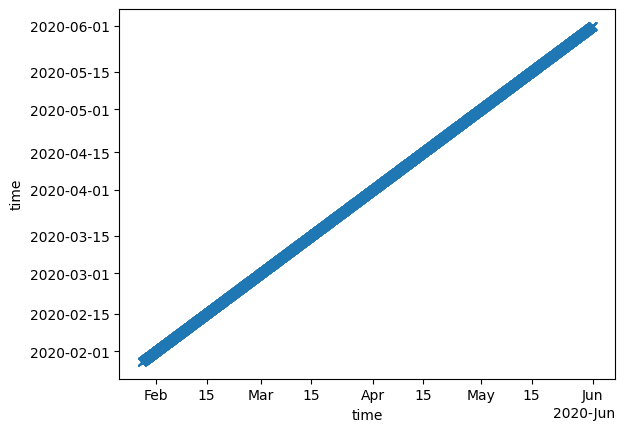

In [ ]:
trainds = xr.concat([trainds_winter, trainds_summer], dim="time")
trainds.time.plot(ls="", marker="x")

## Train dataset statistics

In [ ]:
windwavenet_targets = ["sigWaveHeight", "meanWaveDirection", "meanWavePeriod", "peakPeriod",
                       "continuousPeakPeriod", "dominantDirection", "rmsOrbitalVelocity", "bottomExcursionPerio",
                       "peakPhaseVel", "peakWaveLength", "dissRateDepBreaking", "rollerDissRate"]

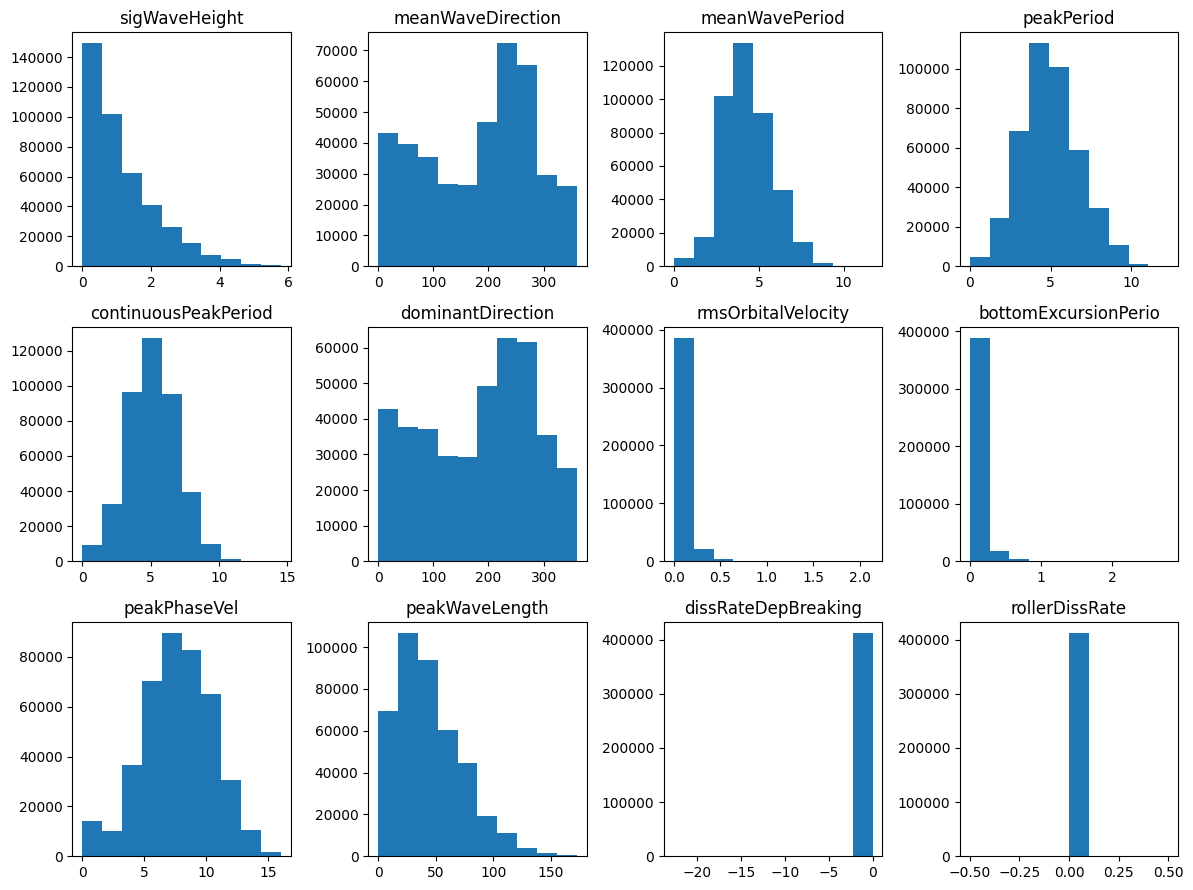

In [ ]:
fig, ax = plt.subplots(3, 4, figsize=(4*3, 3*3))
ax = ax.flatten()

for i, t in enumerate(windwavenet_targets):
    vals = filter_nodes(zarrds[t].isel(time=slice(None, None, 24)), "../src/data/node_selection/node_idx_closest_center_SNS00a_10000.csv").values.flatten()
    ax[i].hist(vals);
    ax[i].set_title(t);

fig.tight_layout();

In [ ]:
C = np.zeros([len(windwavenet_targets), len(windwavenet_targets)])

for i, t1 in enumerate(windwavenet_targets):
    for j, t2 in enumerate(windwavenet_targets):
        if j < i:
            continue
        vals1 = zarrds[t1].isel(time=slice(None, None, 24), nSCHISM_hgrid_node=slice(None, None, 10000)).values.flatten()
        vals2 = zarrds[t2].isel(time=slice(None, None, 24), nSCHISM_hgrid_node=slice(None, None, 10000)).values.flatten()
        C[i,j] = np.corrcoef(vals1, vals2)[0,1]
        print(f"C({t1}, {t2}) = {C[i,j]:.2f}")
        C[j,i] = C[i,j]

C(sigWaveHeight, sigWaveHeight) = 1.00
C(sigWaveHeight, meanWaveDirection) = 0.32
C(sigWaveHeight, meanWavePeriod) = 0.87
C(sigWaveHeight, peakPeriod) = 0.86
C(sigWaveHeight, continuousPeakPeriod) = 0.81
C(sigWaveHeight, dominantDirection) = 0.34
C(sigWaveHeight, rmsOrbitalVelocity) = 0.69
C(sigWaveHeight, bottomExcursionPerio) = 0.75
C(sigWaveHeight, peakPhaseVel) = 0.81
C(sigWaveHeight, peakWaveLength) = 0.92
C(sigWaveHeight, dissRateDepBreaking) = -0.14


/work/ka1176/caroline/gitlab/wind-wave-model-emulator/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/work/ka1176/caroline/gitlab/wind-wave-model-emulator/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


C(sigWaveHeight, rollerDissRate) = nan
C(meanWaveDirection, meanWaveDirection) = 1.00
C(meanWaveDirection, meanWavePeriod) = 0.48
C(meanWaveDirection, peakPeriod) = 0.47
C(meanWaveDirection, continuousPeakPeriod) = 0.60
C(meanWaveDirection, dominantDirection) = 0.94
C(meanWaveDirection, rmsOrbitalVelocity) = 0.31
C(meanWaveDirection, bottomExcursionPerio) = 0.28
C(meanWaveDirection, peakPhaseVel) = 0.56
C(meanWaveDirection, peakWaveLength) = 0.43
C(meanWaveDirection, dissRateDepBreaking) = -0.05
C(meanWaveDirection, rollerDissRate) = nan
C(meanWavePeriod, meanWavePeriod) = 1.00
C(meanWavePeriod, peakPeriod) = 0.98
C(meanWavePeriod, continuousPeakPeriod) = 0.94
C(meanWavePeriod, dominantDirection) = 0.49
C(meanWavePeriod, rmsOrbitalVelocity) = 0.65
C(meanWavePeriod, bottomExcursionPerio) = 0.69
C(meanWavePeriod, peakPhaseVel) = 0.90
C(meanWavePeriod, peakWaveLength) = 0.94
C(meanWavePeriod, dissRateDepBreaking) = -0.15
C(meanWavePeriod, rollerDissRate) = nan
C(peakPeriod, peakPeriod) = 

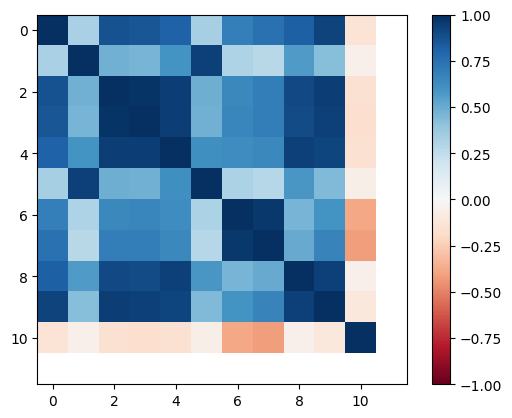

In [ ]:
plt.imshow(C, vmin=-1, vmax=+1, cmap="RdBu")
plt.colorbar()

Create scaling file that can be used in YAML

In [ ]:
for var in ["windSpeedX", "windSpeedY", "elevation", "depthAverageVelX", "depthAverageVelY", 
            "sigWaveHeight", "peakPeriod", "meanWavePeriod", "meanWaveDirection", "meanDirSpreading", 
            "depth", "continuousPeakPeriod", "dominantDirection", "rmsOrbitalVelocity", 
            "bottomExcursionPerio", "peakPhaseVel", "peakWaveLength", "dissRateDepBreaking",
            "rollerDissRate",
           ]:
    if var in windwavenet_targets:
        pvar = "prev_" + var
    else:
        pvar = var
    print(f"{pvar}:")
    print(f"  mean: {trainds[var].mean().values:.4f}")
    print(f"  std: {trainds[var].std().values:.4f}")

windSpeedX:
  mean: 2.5715
  std: 5.8386
windSpeedY:
  mean: 0.5571
  std: 5.3825
elevation:
  mean: 0.2524
  std: 1.1245
depthAverageVelX:
  mean: -0.0078
  std: 0.3868
depthAverageVelY:
  mean: 0.0181
  std: 0.3050
prev_sigWaveHeight:
  mean: 0.7186
  std: 0.8929
prev_peakPeriod:
  mean: 4.1168
  std: 2.2651
prev_meanWavePeriod:
  mean: 3.5995
  std: 1.6455
prev_meanWaveDirection:
  mean: 201.0986
  std: 119.1997
meanDirSpreading:
  mean: 26.4985
  std: 14.7989
depth:
  mean: 14.2043
  std: 14.6055
prev_continuousPeakPeriod:
  mean: 4.1670
  std: 2.5227
prev_dominantDirection:
  mean: 203.4346
  std: 120.7296
prev_rmsOrbitalVelocity:
  mean: 0.0814
  std: 0.1393
prev_bottomExcursionPerio:
  mean: 0.0873
  std: 0.1730
prev_peakPhaseVel:
  mean: 5.4900
  std: 3.5102
prev_peakWaveLength:
  mean: 30.5961
  std: 28.8516
prev_dissRateDepBreaking:
  mean: -0.0378
  std: 0.4854
prev_rollerDissRate:
  mean: 0.0000
  std: 0.0000


In [ ]:
tmp = trainds["dissRateDepBreaking"].where(trainds["dissRateDepBreaking"] > -5.9)
print(np.nanmean(tmp.values), np.nanstd(tmp.values))

-0.027857838 0.25281152


Identify output constraints

In [ ]:
for var in windwavenet_targets:
    print(f"{var}: min = {trainds[var].min().values:.4f} max = {trainds[var].max().values:.4f}")

sigWaveHeight: min = 0.0000 max = 7.4171
meanWaveDirection: min = 0.0000 max = 360.0000
meanWavePeriod: min = 0.0000 max = 25.0000
peakPeriod: min = 0.0000 max = 25.0000
continuousPeakPeriod: min = 0.0000 max = 25.0000
dominantDirection: min = 0.0000 max = 360.0000
rmsOrbitalVelocity: min = 0.0000 max = 2.6929
bottomExcursionPerio: min = 0.0000 max = 4.0490
peakPhaseVel: min = 0.0000 max = 17.2224
peakWaveLength: min = 0.0000 max = 269.4172
dissRateDepBreaking: min = -264.5540 max = 0.0000
rollerDissRate: min = 0.0000 max = 0.0000


In [ ]:
np.quantile(trainds["dissRateDepBreaking"].values, [0.001, 0.01, 0.025, 0.5, 0.975, 0.99])

array([-5.83649956, -0.98379669, -0.12093273,  0.        ,  0.        ,
        0.        ])

In [ ]:
tmp = trainds["dissRateDepBreaking"].where((trainds["dissRateDepBreaking"] < -5.9).compute(), drop=True)
tmp

<xarray.DataArray 'dissRateDepBreaking' (time: 1954, nSCHISM_hgrid_node: 10132)> Size: 79MB
dask.array<where, shape=(1954, 10132), dtype=float32, chunksize=(23, 10132), chunktype=numpy.ndarray>
Coordinates:
  * time                 (time) datetime64[ns] 16kB 2020-01-28T05:00:00 ... 2...
    SCHISM_hgrid_node_x  (nSCHISM_hgrid_node) float32 41kB -9.458e+04 ... 5.3...
    SCHISM_hgrid_node_y  (nSCHISM_hgrid_node) float32 41kB 5.666e+06 ... 5.95...
Dimensions without coordinates: nSCHISM_hgrid_node
Attributes:
    i23d:      1
    location:  node
    mesh:      SCHISM_hgrid

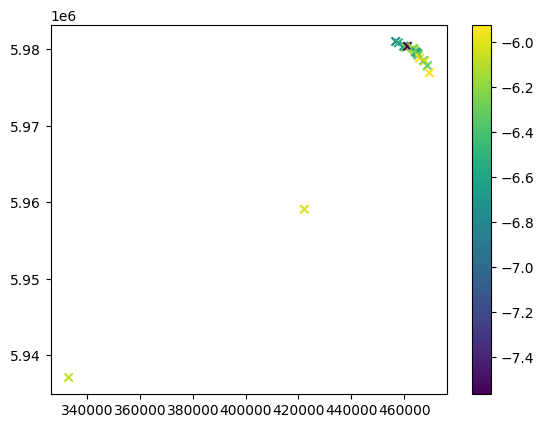

In [ ]:
plt.scatter(tmp.SCHISM_hgrid_node_x.values, tmp.SCHISM_hgrid_node_y.values, marker="x", c=tmp.isel(time=-1).values)
plt.colorbar()

## Statistics

In [ ]:
testds_winter = zarrds.sel(time=slice("2020-07-01", "2020-07-31"))
testds_summer = zarrds.sel(time=slice("2020-12-01", "2020-12-31"))
testds = xr.concat([testds_winter, testds_summer], dim="time")


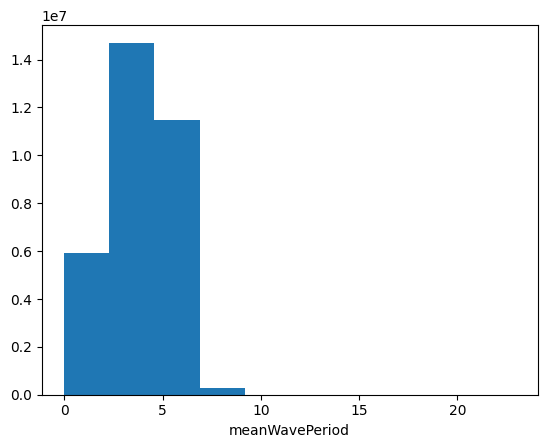

In [ ]:
testds["meanWavePeriod"].plot.hist();

In [ ]:
np.quantile(testds["meanWavePeriod"], [0.01, 0.1, 0.9, 0.99])

array([0.        , 1.9316566 , 6.08446741, 6.85987337])

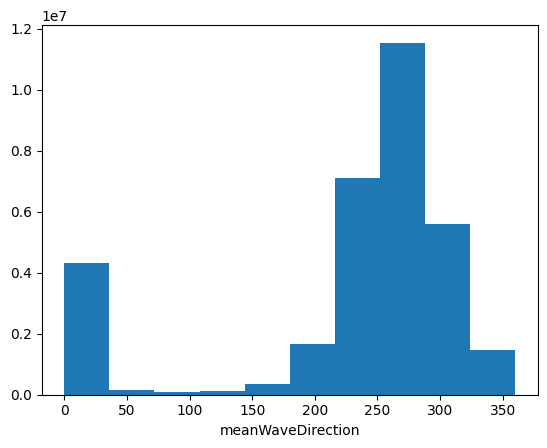

In [ ]:
testds["meanWaveDirection"].plot.hist();

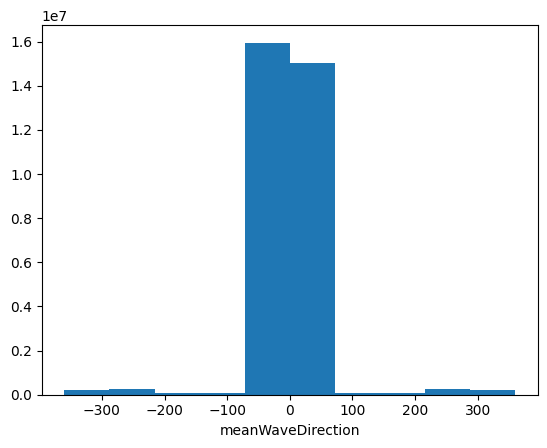

In [ ]:
(testds_winter["meanWaveDirection"] - testds_winter.shift(time=1)["meanWaveDirection"]).plot.hist();